\begin{center}
{\LARGE \textbf{EN3160 Image Processing and Machine Vision}}\\[0.5em]
{\Large Assignment 3 -- Neural Networks}\\[1.5em]

\textbf{Name:} S.A.D. Priyadarshana\\[0.3em]
\textbf{Index:} 230502X\\[0.3em]
\textbf{GitHub:} \href{https://github.com/denethp/CV-Assignment-03}{denethp/CV-Assignment-03}
\end{center}

\vspace{1em}

$\underline{\textbf{Question 1}}$

In [2]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

%matplotlib inline

_ = torch.manual_seed(0)  # fixed seed so my runs are reproducible

In [7]:
# CIFAR-10, normalized to [-1, 1]
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck')

In [8]:
def accuracy(loader, forward):
    # Percentage of correctly classified images in a loader
    correct, total = 0, 0
    with torch.no_grad():
        for inputs, labels in loader:
            x = inputs.view(inputs.shape[0], -1)
            predicted = torch.argmax(forward(x), dim=1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return 100 * correct / total

$\textbf{Baseline: single dense layer with MSE loss}$

Before making the required changes, I first trained the given network as it is, so I have a reference to compare
against. It maps the flattened image ($3 \times 32 \times 32 = 3072$ values) straight to the 10 class scores
with a single weight matrix and is trained with a mean-squared-error loss.

In [10]:
Din = 3 * 32 * 32  # flattened CIFAR-10 image
K = 10             # number of classes
std = 1e-5

w = torch.randn(Din, K) * std
b = torch.zeros(K)

iterations = 20
lr = 2e-6
lr_decay = 0.9
reg = 0
loss_history = []

for t in range(iterations):
    running_loss = 0.0
    for inputs, labels in trainloader:
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()

        # Forward pass
        y_pred = x_train.mm(w) + b

        # MSE loss with L2 regularization
        loss = (1 / Ntr) * torch.sum((y_pred - y_train_onehot) ** 2) + reg * torch.sum(w ** 2)
        loss_history.append(loss.item())
        running_loss += loss.item()

        # Backpropagation
        dy_pred = (2.0 / Ntr) * (y_pred - y_train_onehot)
        dw = x_train.t().mm(dy_pred) + reg * w
        db = dy_pred.sum(dim=0)

        w -= lr * dw
        b -= lr * db

    print(f'Epoch {t + 1}/{iterations}, Loss: {running_loss / len(trainloader):.4f}')
    lr *= lr_decay

Epoch 1/20, Loss: 0.9770
Epoch 2/20, Loss: 0.9499
Epoch 3/20, Loss: 0.9361
Epoch 4/20, Loss: 0.9275
Epoch 5/20, Loss: 0.9216
Epoch 6/20, Loss: 0.9172
Epoch 7/20, Loss: 0.9138
Epoch 8/20, Loss: 0.9111
Epoch 9/20, Loss: 0.9088
Epoch 10/20, Loss: 0.9070
Epoch 11/20, Loss: 0.9054
Epoch 12/20, Loss: 0.9041
Epoch 13/20, Loss: 0.9029
Epoch 14/20, Loss: 0.9020
Epoch 15/20, Loss: 0.9011
Epoch 16/20, Loss: 0.9004
Epoch 17/20, Loss: 0.8997
Epoch 18/20, Loss: 0.8991
Epoch 19/20, Loss: 0.8986
Epoch 20/20, Loss: 0.8982


Training accuracy: 32.23%
Test accuracy: 32.43%


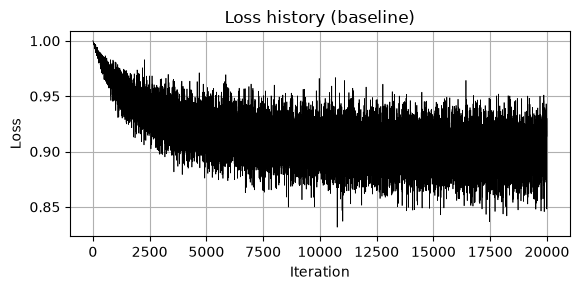

In [11]:
baseline_train_acc = accuracy(trainloader, lambda x: x.mm(w) + b)
baseline_test_acc = accuracy(testloader, lambda x: x.mm(w) + b)
print(f'Training accuracy: {baseline_train_acc:.2f}%')
print(f'Test accuracy: {baseline_test_acc:.2f}%')

plt.figure(figsize=(6, 3))
plt.plot(loss_history, color='k', linewidth=0.5)
plt.title('Loss history (baseline)')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.grid(True)
plt.tight_layout()
plt.show()

$\textbf{(a) Adding a middle layer with 100 nodes and sigmoid activation}$

I added a hidden layer of $H = 100$ nodes between the input and the output, so the network becomes

$$\mathbf{h} = \sigma(\mathbf{x} W_1 + \mathbf{b}_1), \qquad \hat{\mathbf{y}} = \mathbf{h} W_2 + \mathbf{b}_2,$$

with $W_1 \in \mathbb{R}^{3072 \times 100}$ and $W_2 \in \mathbb{R}^{100 \times 10}$. I still compute the forward pass and the
gradients by hand. Going backwards from the output gradient $\partial L / \partial \hat{\mathbf{y}}$:

$$\frac{\partial L}{\partial W_2} = \mathbf{h}^T \frac{\partial L}{\partial \hat{\mathbf{y}}}, \qquad
\frac{\partial L}{\partial \mathbf{z}_1} = \Big(\frac{\partial L}{\partial \hat{\mathbf{y}}} W_2^T\Big) \odot \mathbf{h} \odot (1 - \mathbf{h}), \qquad
\frac{\partial L}{\partial W_1} = \mathbf{x}^T \frac{\partial L}{\partial \mathbf{z}_1},$$

where $\mathbf{h} \odot (1 - \mathbf{h})$ is the derivative of the sigmoid. I verified these gradients against numerical
(finite-difference) gradients before training.

The tiny initialization ($10^{-5}$) of the single-layer network does not work with a hidden layer, because every
hidden node would output $\sigma(0) = 0.5$ and the signal would barely reach the output. So I initialized each weight
matrix with standard deviation $1/\sqrt{\text{fan-in}}$. To speed up training, I loaded the whole dataset onto the GPU
once and drew the mini-batches from it directly.

In [12]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

def to_device_tensors(dataset):
    # Same preprocessing as the transform above: [0, 1] -> [-1, 1], then flatten (C, H, W)
    x = torch.tensor(dataset.data, dtype=torch.float32).permute(0, 3, 1, 2) / 255.0
    x = ((x - 0.5) / 0.5).reshape(len(dataset), -1)
    y = torch.tensor(dataset.targets)
    return x.to(device), y.to(device)

X_train, Y_train = to_device_tensors(trainset)
X_test, Y_test = to_device_tensors(testset)
print('Train:', tuple(X_train.shape), ' Test:', tuple(X_test.shape))

Device: cuda
Train: (50000, 3072)  Test: (10000, 3072)


In [13]:
Din = 3 * 32 * 32
H = 100  # hidden nodes
K = 10

def init_params(seed=0):
    g = torch.Generator(device=device).manual_seed(seed)
    w1 = torch.randn(Din, H, device=device, generator=g) / Din ** 0.5
    b1 = torch.zeros(H, device=device)
    w2 = torch.randn(H, K, device=device, generator=g) / H ** 0.5
    b2 = torch.zeros(K, device=device)
    return [w1, b1, w2, b2]

def forward(x, params):
    w1, b1, w2, b2 = params
    h = torch.sigmoid(x.mm(w1) + b1)  # hidden layer
    y_pred = h.mm(w2) + b2            # output scores
    return y_pred, h

def evaluate(X, Y, params):
    with torch.no_grad():
        predicted = torch.argmax(forward(X, params)[0], dim=1)
    return 100 * (predicted == Y).float().mean().item()

def train(loss_fn, epochs=10, lr=0.05, lr_decay=0.9, reg=0.0, seed=0):
    # Mini-batch gradient descent with manually computed gradients
    params = init_params(seed)
    w1, b1, w2, b2 = params
    g = torch.Generator(device=device).manual_seed(seed)
    N = X_train.shape[0]
    loss_history, epoch_loss = [], []

    for epoch in range(epochs):
        perm = torch.randperm(N, device=device, generator=g)
        running_loss = 0.0
        for i in range(0, N, batch_size):
            idx = perm[i:i + batch_size]
            x = X_train[idx]
            y_onehot = nn.functional.one_hot(Y_train[idx], K).float()

            # Forward pass
            y_pred, h = forward(x, params)
            loss, dy_pred = loss_fn(y_pred, y_onehot)
            loss = loss + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))

            # Backpropagation
            dw2 = h.t().mm(dy_pred) + 2 * reg * w2
            db2 = dy_pred.sum(dim=0)
            dz1 = dy_pred.mm(w2.t()) * h * (1 - h)  # through the sigmoid
            dw1 = x.t().mm(dz1) + 2 * reg * w1
            db1 = dz1.sum(dim=0)

            # Parameter update
            w1 -= lr * dw1
            b1 -= lr * db1
            w2 -= lr * dw2
            b2 -= lr * db2

            loss_history.append(loss.item())
            running_loss += loss.item()

        epoch_loss.append(running_loss / (N // batch_size))
        print(f'Epoch {epoch + 1}/{epochs}, Loss: {epoch_loss[-1]:.4f}')
        lr *= lr_decay

    return params, loss_history, epoch_loss

To see the effect of the hidden layer on its own, I first trained it with the same MSE loss as the baseline, for 10 epochs.

In [14]:
def mse_loss(y_pred, y_onehot):
    n = y_pred.shape[0]
    loss = torch.sum((y_pred - y_onehot) ** 2) / n
    dy_pred = 2.0 * (y_pred - y_onehot) / n
    return loss, dy_pred

params_mse, loss_history_mse, epoch_loss_mse = train(mse_loss, epochs=10, lr=0.05)

mse_train_acc = evaluate(X_train, Y_train, params_mse)
mse_test_acc = evaluate(X_test, Y_test, params_mse)
print(f'Training accuracy: {mse_train_acc:.2f}%')
print(f'Test accuracy: {mse_test_acc:.2f}%')

Epoch 1/10, Loss: 2.0829
Epoch 2/10, Loss: 0.8287
Epoch 3/10, Loss: 0.7952
Epoch 4/10, Loss: 0.7732
Epoch 5/10, Loss: 0.7589
Epoch 6/10, Loss: 0.7472
Epoch 7/10, Loss: 0.7385
Epoch 8/10, Loss: 0.7321
Epoch 9/10, Loss: 0.7258
Epoch 10/10, Loss: 0.7208
Training accuracy: 47.71%
Test accuracy: 44.01%


$\textbf{(b) Using the cross-entropy loss}$

Next, I replaced the MSE loss with the cross-entropy loss. The output scores $\hat{\mathbf{y}}$ are first turned into class
probabilities with the softmax function, and the loss is the average negative log-probability of the correct class:

$$p_k = \frac{e^{\hat{y}_k}}{\sum_{j=1}^{K} e^{\hat{y}_j}}, \qquad L = -\frac{1}{N} \sum_{i=1}^{N} \sum_{k=1}^{K} y_{ik} \log p_{ik}.$$

The gradient of this loss with respect to the output scores simplifies to

$$\frac{\partial L}{\partial \hat{\mathbf{y}}} = \frac{1}{N}(\mathbf{p} - \mathbf{y}),$$

so only the output gradient changes, and the rest of my backpropagation through the hidden layer stays the same. I
computed the softmax through `log_softmax`, which subtracts the largest score first, so that large scores cannot
overflow the exponential. I also checked this gradient numerically, and kept every other setting identical to the
MSE run (10 epochs, learning rate 0.05, decay 0.9) so that the two losses can be compared fairly.

In [15]:
def cross_entropy_loss(y_pred, y_onehot):
    n = y_pred.shape[0]
    log_p = torch.log_softmax(y_pred, dim=1)  # numerically stable log-softmax
    loss = -torch.sum(y_onehot * log_p) / n
    dy_pred = (torch.exp(log_p) - y_onehot) / n
    return loss, dy_pred

params_ce, loss_history_ce, epoch_loss_ce = train(cross_entropy_loss, epochs=10, lr=0.05)

ce_train_acc = evaluate(X_train, Y_train, params_ce)
ce_test_acc = evaluate(X_test, Y_test, params_ce)
print(f'Training accuracy: {ce_train_acc:.2f}%')
print(f'Test accuracy: {ce_test_acc:.2f}%')

Epoch 1/10, Loss: 1.8510
Epoch 2/10, Loss: 1.7234
Epoch 3/10, Loss: 1.6740
Epoch 4/10, Loss: 1.6395
Epoch 5/10, Loss: 1.6123
Epoch 6/10, Loss: 1.5899
Epoch 7/10, Loss: 1.5693
Epoch 8/10, Loss: 1.5524
Epoch 9/10, Loss: 1.5369
Epoch 10/10, Loss: 1.5223
Training accuracy: 48.55%
Test accuracy: 45.94%


$\textbf{(c) Results after 10 epochs}$

The final network (100-node sigmoid hidden layer with the cross-entropy loss) was trained for 10 epochs in part (b).
Below I plot its loss next to the MSE run and compare the accuracies of all three networks I trained.

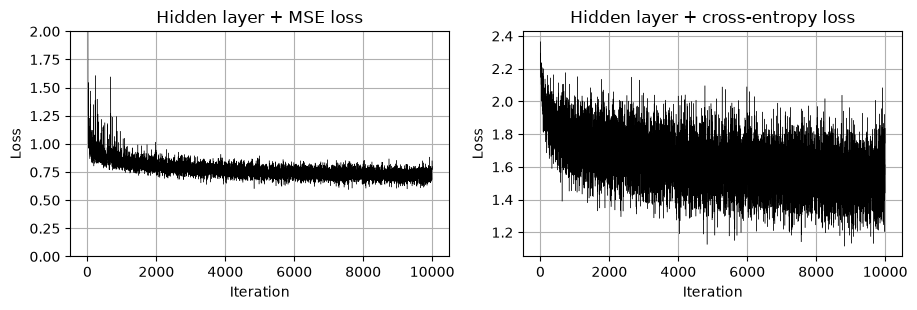

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(9.3, 3.2))
curves = [(loss_history_mse, 'Hidden layer + MSE loss'),
          (loss_history_ce, 'Hidden layer + cross-entropy loss')]
for ax, (hist, title) in zip(axes, curves):
    ax.plot(hist, color='k', linewidth=0.3)
    ax.set_title(title)
    ax.set_xlabel('Iteration')
    ax.set_ylabel('Loss')
    ax.grid(True)
axes[0].set_ylim(0, 2)  # the first few MSE iterations are much larger
plt.tight_layout()
plt.show()

In [17]:
results = [('Single layer + MSE (20 epochs)', baseline_train_acc, baseline_test_acc),
           ('Hidden layer + MSE (10 epochs)', mse_train_acc, mse_test_acc),
           ('Hidden layer + cross-entropy (10 epochs)', ce_train_acc, ce_test_acc)]

print(f"{'Network':<42}{'Train acc':>11}{'Test acc':>11}")
for name, tr, te in results:
    print(f'{name:<42}{tr:>10.2f}%{te:>10.2f}%')

Network                                     Train acc   Test acc
Single layer + MSE (20 epochs)                 32.23%     32.43%
Hidden layer + MSE (10 epochs)                 47.71%     44.01%
Hidden layer + cross-entropy (10 epochs)       48.55%     45.94%


$\textbf{Discussion:}$ adding the 100-node sigmoid hidden layer gave the biggest improvement. With the same MSE loss, the
test accuracy rose from $32.43\%$ (single layer, 20 epochs) to $44.01\%$ in only 10 epochs. The single-layer network is a
linear classifier: it can only learn one template per class, and its training and test accuracies were almost equal
($32.23\%$ vs $32.43\%$), which shows it was limited by its capacity rather than by overfitting. The sigmoid hidden layer
lets the network learn non-linear combinations of pixels, so it fits the data much better.

Switching from MSE to cross-entropy, with every other setting unchanged, improved the test accuracy further to
$45.94\%$ (training $48.55\%$). I think this is because the cross-entropy gradient $(\mathbf{p} - \mathbf{y})/N$ keeps pushing
the score of the correct class up until it dominates through the softmax, whereas MSE forces all ten outputs towards
exact 0/1 targets and spends effort on the wrong classes' scores even when the prediction is already correct. The loss
curves also show this: the MSE run had a large spike in the first iterations before settling, while the cross-entropy loss
fell smoothly from the start. The gap between training and test accuracy also became smaller with cross-entropy
($2.6$ points vs $3.7$ points for MSE).

The cross-entropy loss was still decreasing at the end of the 10 epochs, so training for longer (or with a larger
learning rate) would likely raise the accuracy further. However, a fully connected network on raw pixels ignores the
spatial structure of the image, so it cannot get close to the accuracy of a convolutional network on CIFAR-10.

$\underline{\textbf{Question 2}}$

In [3]:
import time
import torch.nn.functional as F
import torch.optim as optim

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# MNIST, normalized with the dataset mean and standard deviation
mnist_train = torchvision.datasets.MNIST(root='./data', train=True, download=True)
mnist_test = torchvision.datasets.MNIST(root='./data', train=False, download=True)

def mnist_to_device(dataset):
    x = dataset.data.float().unsqueeze(1) / 255.0  # (N, 1, 28, 28)
    x = (x - 0.1307) / 0.3081
    return x.to(device), dataset.targets.to(device)

Xm_train, Ym_train = mnist_to_device(mnist_train)
Xm_test, Ym_test = mnist_to_device(mnist_test)
print('Train:', tuple(Xm_train.shape), ' Test:', tuple(Xm_test.shape))

Train: (60000, 1, 28, 28)  Test: (10000, 1, 28, 28)


To train both networks under exactly the same conditions, I wrote one training function and use it for both models.
It uses the Adam optimizer (learning rate $10^{-3}$), mini-batches of 64 images and the cross-entropy loss, and trains
for 10 epochs. After every epoch it records the training and test loss and accuracy, so that I can plot the learning
curves later. The training values are averaged over the epoch while the model is in training mode, and the test values
are computed in evaluation mode. As in Question 1, I kept the whole dataset on the GPU and drew the batches from it
directly.

In [4]:
def evaluate_model(model, X, Y, batch=1000):
    # Average loss and accuracy (%) in evaluation mode
    model.eval()
    total_loss, correct = 0.0, 0
    with torch.no_grad():
        for i in range(0, len(X), batch):
            out = model(X[i:i + batch])
            total_loss += F.cross_entropy(out, Y[i:i + batch], reduction='sum').item()
            correct += (out.argmax(dim=1) == Y[i:i + batch]).sum().item()
    return total_loss / len(X), 100 * correct / len(X)

def fit(model, epochs=10, lr=1e-3, batch=64, seed=0):
    torch.manual_seed(seed)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    history = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': []}
    N = len(Xm_train)

    for epoch in range(epochs):
        model.train()
        start = time.time()
        perm = torch.randperm(N, device=device)
        total_loss, correct = 0.0, 0
        for i in range(0, N, batch):
            idx = perm[i:i + batch]
            x, y = Xm_train[idx], Ym_train[idx]

            out = model(x)
            loss = F.cross_entropy(out, y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(y)
            correct += (out.argmax(dim=1) == y).sum().item()

        test_loss, test_acc = evaluate_model(model, Xm_test, Ym_test)
        history['train_loss'].append(total_loss / N)
        history['train_acc'].append(100 * correct / N)
        history['test_loss'].append(test_loss)
        history['test_acc'].append(test_acc)
        print(f"Epoch {epoch + 1}/{epochs}: "
              f"train loss {history['train_loss'][-1]:.4f}, train acc {history['train_acc'][-1]:.2f}% | "
              f"test loss {test_loss:.4f}, test acc {test_acc:.2f}% ({time.time() - start:.1f}s)")
    return history

$\textbf{(a) LeNet-5}$

I built LeNet-5 following the original design by LeCun et al. (1998). Since MNIST images are $28 \times 28$ rather than
the $32 \times 32$ inputs of the original network, I padded the first convolution by 2 pixels so that the feature map
sizes are the same as in the paper:

- C1: $5 \times 5$ convolution with 6 filters and padding 2, tanh $\rightarrow$ $6 \times 28 \times 28$
- S2: $2 \times 2$ average pooling $\rightarrow$ $6 \times 14 \times 14$
- C3: $5 \times 5$ convolution with 16 filters, tanh $\rightarrow$ $16 \times 10 \times 10$
- S4: $2 \times 2$ average pooling $\rightarrow$ $16 \times 5 \times 5$
- C5: fully connected, 120 units, tanh
- F6: fully connected, 84 units, tanh
- Output: fully connected, 10 units (one score per digit)

I kept the original tanh activations and average pooling, so that this network represents the classic design and the
modern network in part (b) shows the effect of newer techniques.

In [5]:
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.c1 = nn.Conv2d(1, 6, kernel_size=5, padding=2)
        self.s2 = nn.AvgPool2d(2)
        self.c3 = nn.Conv2d(6, 16, kernel_size=5)
        self.s4 = nn.AvgPool2d(2)
        self.c5 = nn.Linear(16 * 5 * 5, 120)
        self.f6 = nn.Linear(120, 84)
        self.out = nn.Linear(84, 10)

    def forward(self, x):
        x = self.s2(torch.tanh(self.c1(x)))
        x = self.s4(torch.tanh(self.c3(x)))
        x = torch.flatten(x, 1)
        x = torch.tanh(self.c5(x))
        x = torch.tanh(self.f6(x))
        return self.out(x)

torch.manual_seed(0)
lenet = LeNet5().to(device)
print(f'LeNet-5 parameters: {sum(p.numel() for p in lenet.parameters()):,}')

history_lenet = fit(lenet, epochs=10)
print(f"\nLeNet-5 after 10 epochs: training accuracy {history_lenet['train_acc'][-1]:.2f}%, "
      f"test accuracy {history_lenet['test_acc'][-1]:.2f}%")

LeNet-5 parameters: 61,706
Epoch 1/10: train loss 0.2575, train acc 92.54% | test loss 0.0886, test acc 97.55% (6.3s)
Epoch 2/10: train loss 0.0735, train acc 97.81% | test loss 0.0607, test acc 98.09% (5.0s)
Epoch 3/10: train loss 0.0524, train acc 98.36% | test loss 0.0526, test acc 98.27% (4.7s)
Epoch 4/10: train loss 0.0396, train acc 98.77% | test loss 0.0542, test acc 98.28% (4.4s)
Epoch 5/10: train loss 0.0334, train acc 98.95% | test loss 0.0458, test acc 98.39% (4.5s)
Epoch 6/10: train loss 0.0277, train acc 99.12% | test loss 0.0463, test acc 98.64% (4.7s)
Epoch 7/10: train loss 0.0242, train acc 99.21% | test loss 0.0380, test acc 98.71% (4.6s)
Epoch 8/10: train loss 0.0205, train acc 99.35% | test loss 0.0491, test acc 98.57% (4.7s)
Epoch 9/10: train loss 0.0170, train acc 99.46% | test loss 0.0468, test acc 98.56% (4.6s)
Epoch 10/10: train loss 0.0148, train acc 99.50% | test loss 0.0380, test acc 98.80% (4.8s)

LeNet-5 after 10 epochs: training accuracy 99.50%, test accur

$\textbf{(b) A modern small CNN with batch normalization and dropout}$

For the modern network I used three convolutional blocks. Each block is a $3 \times 3$ convolution, batch normalization,
a ReLU activation and $2 \times 2$ max pooling, and the number of filters doubles from block to block:

- Block 1: 32 filters $\rightarrow$ $32 \times 14 \times 14$
- Block 2: 64 filters $\rightarrow$ $64 \times 7 \times 7$
- Block 3: 128 filters $\rightarrow$ $128 \times 3 \times 3$
- Classifier: dropout (0.5), fully connected layer with 128 units and ReLU, dropout (0.5), and a final layer with 10 outputs

Compared with LeNet-5, I made the following changes:

- ReLU instead of tanh, which does not saturate, so the gradients stay large in the early layers.
- Batch normalization after every convolution, which keeps the input to each layer normalized during training. This
  makes training faster and more stable. The convolutions have no bias because batch normalization adds its own shift.
- Max pooling instead of average pooling, which keeps the strongest response in each region.
- Dropout in the classifier, which randomly switches off half of the units during training so that the network cannot
  rely on a few specific features. This acts as a regularizer against overfitting.
- Three convolutional layers with more filters, so it can learn richer features.

I trained it with exactly the same `fit` function and settings as LeNet-5 (Adam, learning rate $10^{-3}$, batch size 64,
10 epochs).

In [6]:
class ModernCNN(nn.Module):
    def __init__(self):
        super().__init__()
        def block(c_in, c_out):
            return nn.Sequential(
                nn.Conv2d(c_in, c_out, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(c_out),
                nn.ReLU(),
                nn.MaxPool2d(2))
        self.features = nn.Sequential(block(1, 32), block(32, 64), block(64, 128))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(128 * 3 * 3, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 10))

    def forward(self, x):
        return self.classifier(self.features(x))

torch.manual_seed(0)
cnn = ModernCNN().to(device)
print(f'Modern CNN parameters: {sum(p.numel() for p in cnn.parameters()):,}')

history_cnn = fit(cnn, epochs=10)
print(f"\nModern CNN after 10 epochs: training accuracy {history_cnn['train_acc'][-1]:.2f}%, "
      f"test accuracy {history_cnn['test_acc'][-1]:.2f}%")

Modern CNN parameters: 241,770
Epoch 1/10: train loss 0.2100, train acc 93.56% | test loss 0.0489, test acc 98.38% (7.0s)
Epoch 2/10: train loss 0.0832, train acc 97.61% | test loss 0.0281, test acc 99.10% (5.8s)
Epoch 3/10: train loss 0.0660, train acc 98.10% | test loss 0.0236, test acc 99.23% (7.6s)
Epoch 4/10: train loss 0.0567, train acc 98.39% | test loss 0.0228, test acc 99.24% (7.1s)
Epoch 5/10: train loss 0.0500, train acc 98.56% | test loss 0.0230, test acc 99.26% (7.9s)
Epoch 6/10: train loss 0.0439, train acc 98.71% | test loss 0.0218, test acc 99.19% (8.1s)
Epoch 7/10: train loss 0.0384, train acc 98.86% | test loss 0.0247, test acc 99.20% (8.4s)
Epoch 8/10: train loss 0.0377, train acc 98.87% | test loss 0.0216, test acc 99.32% (8.4s)
Epoch 9/10: train loss 0.0342, train acc 98.98% | test loss 0.0231, test acc 99.39% (8.3s)
Epoch 10/10: train loss 0.0313, train acc 99.06% | test loss 0.0219, test acc 99.34% (8.2s)

Modern CNN after 10 epochs: training accuracy 99.06%, tes

$\textbf{(c) Learning curves and confusion matrices}$

I plotted the per-epoch accuracy and loss that `fit` logged for both models, with the training values as dashed lines
and the test values as solid lines.

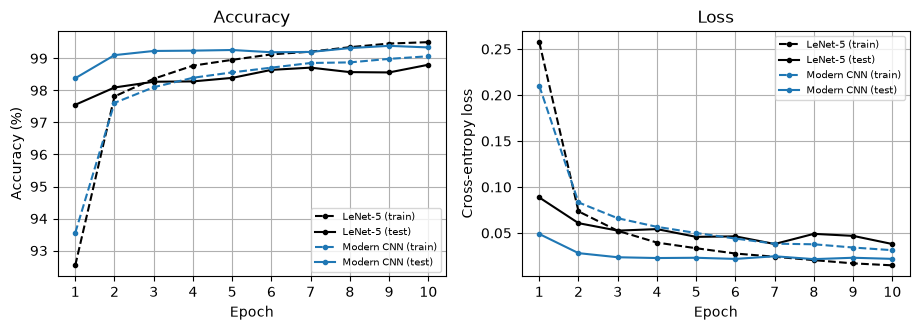

In [7]:
epochs = range(1, 11)
models = [(history_lenet, 'LeNet-5', 'k'), (history_cnn, 'Modern CNN', 'tab:blue')]

fig, axes = plt.subplots(1, 2, figsize=(9.3, 3.4))
for hist, name, color in models:
    axes[0].plot(epochs, hist['train_acc'], '--o', color=color, markersize=3, label=f'{name} (train)')
    axes[0].plot(epochs, hist['test_acc'], '-o', color=color, markersize=3, label=f'{name} (test)')
    axes[1].plot(epochs, hist['train_loss'], '--o', color=color, markersize=3, label=f'{name} (train)')
    axes[1].plot(epochs, hist['test_loss'], '-o', color=color, markersize=3, label=f'{name} (test)')

axes[0].set_title('Accuracy')
axes[0].set_ylabel('Accuracy (%)')
axes[1].set_title('Loss')
axes[1].set_ylabel('Cross-entropy loss')
for ax in axes:
    ax.set_xlabel('Epoch')
    ax.set_xticks(epochs)
    ax.grid(True)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

Next, I computed the confusion matrix of each model on the 10,000 test images. Row $i$, column $j$ counts the test
images of digit $i$ that the model classified as $j$, so the correct predictions lie on the diagonal and every
off-diagonal entry is a mistake.

LeNet-5: 120 misclassified test images
  most common mistake: 2 predicted as 7 (8 times)
Modern CNN: 66 misclassified test images
  most common mistake: 9 predicted as 4 (9 times)


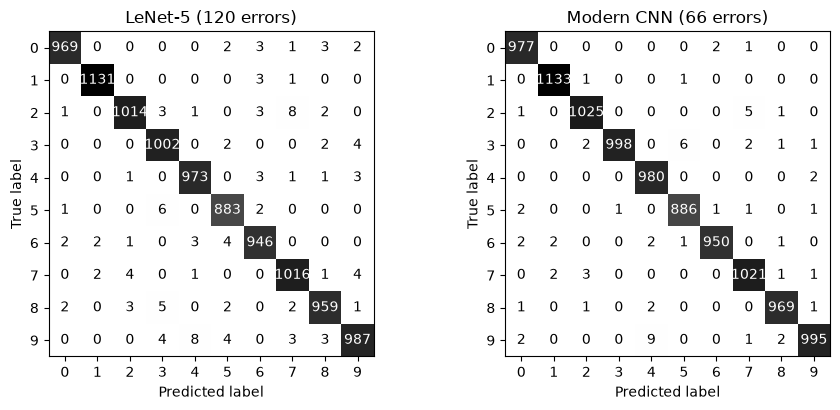

In [8]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

def predict(model, X, batch=1000):
    model.eval()
    with torch.no_grad():
        return torch.cat([model(X[i:i + batch]).argmax(dim=1) for i in range(0, len(X), batch)])

y_true = Ym_test.cpu().numpy()
fig, axes = plt.subplots(1, 2, figsize=(9.3, 4.2))
for ax, (model, name) in zip(axes, [(lenet, 'LeNet-5'), (cnn, 'Modern CNN')]):
    y_pred = predict(model, Xm_test).cpu().numpy()
    cm = confusion_matrix(y_true, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(ax=ax, cmap='Greys', colorbar=False)
    errors = cm.sum() - cm.trace()
    ax.set_title(f'{name} ({errors} errors)')
    print(f'{name}: {errors} misclassified test images')

    # Most frequent mistake (largest off-diagonal entry)
    off = cm.copy()
    off[list(range(10)), list(range(10))] = 0
    i, j = divmod(off.argmax(), 10)
    print(f'  most common mistake: {i} predicted as {j} ({off[i, j]} times)')
plt.tight_layout()
plt.show()

$\textbf{Discussion:}$ both networks reached a high accuracy on MNIST within 10 epochs, but the modern CNN was clearly
better. LeNet-5 finished with $99.50\%$ training and $98.80\%$ test accuracy (120 misclassified test images), while my
modern CNN finished with $99.06\%$ training and $99.34\%$ test accuracy (66 errors), so it made about $45\%$ fewer mistakes
on the same test set. It was also better from the very first epoch ($98.38\%$ test accuracy after one epoch against
$97.55\%$ for LeNet-5), which I think comes from batch normalization and ReLU: batch normalization keeps the inputs of each
layer well scaled, and ReLU does not saturate like tanh, so the gradients stay large and the first epoch already makes a lot
of progress.

The learning curves show a difference in how the two models generalize. For LeNet-5 the training accuracy passed the
test accuracy from epoch 3 onwards, and its test loss stopped improving and started to fluctuate after epoch 7
(between $0.038$ and $0.049$) even though the training loss kept falling, which is the beginning of overfitting. For the
modern CNN the training accuracy stayed *below* the test accuracy for all 10 epochs. This does not mean the model is
worse on the training data: the training accuracy is measured while dropout is switching off half of the classifier units,
whereas the test accuracy is measured with all units active. Together with its stable test loss (around $0.022$ from
epoch 4), this shows that dropout prevented overfitting even though the modern CNN has about four times as many
parameters ($241{,}770$ against $61{,}706$).

The confusion matrices show that both models make the same kind of mistakes, between digits that look alike when
written by hand. For LeNet-5 the most common errors were 2 predicted as 7 and 9 predicted as 4 (8 times each), followed by
5 predicted as 3. The modern CNN removed most of these, and its remaining errors are spread thinly over the matrix; its most
common mistake was 9 predicted as 4 (9 times), which are the hardest pair because a 4 with a closed top looks very similar
to a 9. The price of the better accuracy is computation: each epoch of the modern CNN took about 8 s compared with about
5 s for LeNet-5 on my GPU.